In [1]:
import sys
import matplotlib
import numpy as np
import pandas as pd
import sklearn

# Печатаем версии среды и основных библиотек одним блоком.
print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)


Python: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]
NumPy: 2.5.3
Pandas: 3.0.6
Matplotlib: 3.11.2
scikit-learn: 1.9.1


In [2]:
# Скрываем только предупреждения о будущих изменениях API;
# остальные предупреждения оставляем видимыми.
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Базовые библиотеки для вычислений, таблиц и графиков.
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Компоненты scikit-learn сгруппированы по назначению.
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Все случайные операции используют одно значение для воспроизводимости.
RANDOM_STATE = 1004
DATA_ID = 16
TEST_SIZE = 0.20
SCORING = "f1_macro"


Источник: локальная копия ML_Lab1_Datasets\variant_04.csv
Размер X: (2000, 64)
Классы: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


,att1,att2,att3,att4,att5,att6,att7,att8,att9,att10,...,att55,att56,att57,att58,att59,att60,att61,att62,att63,att64
0,-10.297008,-11.666789,11.560669,-2.081316,4.044656,4.086815,-2.558072,-8.476935,2.138135,3.503082,...,1.078083,0.921927,0.496387,-0.643667,0.284104,0.286555,0.348625,1.814691,-1.351353,-0.473910
1,-5.036009,-12.885333,0.161155,0.592460,3.123534,4.220469,-6.411771,-6.335328,-0.244622,1.346073,...,0.942353,2.938791,1.429883,-2.336344,1.281628,-0.098321,0.582357,0.485792,0.642451,0.613107
2,-9.639157,-6.655898,0.388687,-1.717650,0.300346,3.400769,-7.240785,-1.659405,-0.874005,4.153403,...,-0.413174,-0.023028,-0.025265,1.259838,-0.441360,-0.960094,1.995843,1.097748,0.827182,-1.767840
3,-6.650375,-7.043851,4.104350,-2.342780,3.494658,3.924822,-9.874812,-6.556576,-1.364269,1.153308,...,-0.961236,-1.043815,-0.204508,-1.981150,0.982438,-0.144233,-1.449328,-0.913552,-0.771735,0.304992
4,-10.664524,-10.974133,0.194391,0.453885,2.193088,-3.304663,-8.376592,-4.241146,2.964818,-0.949622,...,0.152957,1.448160,-1.254907,-3.481295,-0.563889,1.529335,0.510399,0.298318,-0.943213,1.149847


,dtype,n_unique,n_missing,missing_share
att1,float64,1994,0,0.0
att2,float64,1994,0,0.0
att3,float64,1994,0,0.0
att4,float64,1994,0,0.0
att5,float64,1994,0,0.0
...,...,...,...,...
att60,float64,1994,0,0.0
att61,float64,1994,0,0.0
att62,float64,1994,0,0.0
att63,float64,1993,0,0.0


,count,share
class,,
1,200,0.1
2,200,0.1
3,200,0.1
4,200,0.1
5,200,0.1
6,200,0.1
7,200,0.1
8,200,0.1
9,200,0.1


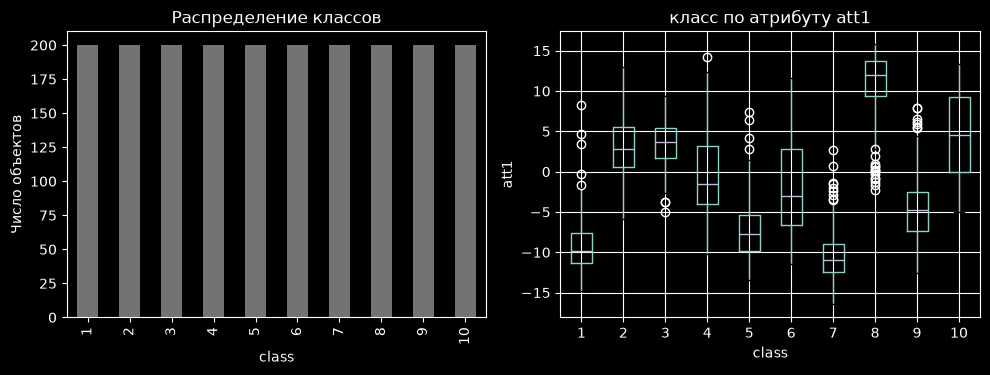

In [3]:
from IPython.display import display
from pathlib import Path

# Сначала пытаемся использовать приложенную локальную копию.
example_path = Path("ML_Lab1_Datasets") / "variant_04.csv"

if example_path.exists():
    frame = pd.read_csv(example_path)
    print("Источник: локальная копия", example_path)
else:
    # Резервный вариант нужен, если архив с данными не был распакован.
    data = fetch_openml(data_id=16, as_frame=True)
    frame = data.data.copy()
    frame["class"] = data.target
    print("Источник: OpenML, data_id 16")

X = frame.drop(columns=["class"]).copy()
y = pd.to_numeric(frame["class"]).astype("int64")

# Проверяем размерность, классы и первые строки до дальнейшей обработки.
print("Размер X:", X.shape)
print("Классы:", sorted(y.unique()))
display(X.head())

# Карточка признаков объединяет тип, число значений и статистику пропусков.
data_card = pd.DataFrame({
    "dtype": X.dtypes.astype(str),
    "n_unique": X.nunique(dropna=True),
    "n_missing": X.isna().sum(),
    "missing_share": X.isna().mean().round(3),
})

# Отдельно оцениваем абсолютный и относительный размер каждого класса.
class_table = pd.DataFrame({
    "count": y.value_counts().sort_index(),
    "share": y.value_counts(normalize=True).sort_index().round(3),
})

# display удобнее print для просмотра таблиц внутри Jupyter Notebook.
display(data_card)
display(class_table)

# На одном рисунке показываем баланс классов и распределение возраста.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Столбчатая диаграмма позволяет быстро увидеть дисбаланс классов.
y.value_counts().sort_index().plot.bar(ax=axes[0], color="0.45")
axes[0].set_title("Распределение классов")
axes[0].set_xlabel("class")
axes[0].set_ylabel("Число объектов")

plot_frame = pd.DataFrame({"att1": X["att1"], "class": y})
# Boxplot показывает медиану, разброс и возможные выбросы по каждому классу.
plot_frame.boxplot(column="att1", by="class", ax=axes[1])
axes[1].set_title("класс по атрибуту att1")
axes[1].set_xlabel("class")
axes[1].set_ylabel("att1")

# Pandas добавляет общий заголовок автоматически — убираем его перед выводом.
plt.suptitle("")
plt.tight_layout()
plt.show()


In [4]:
#Далее идёт уже ML
## 5. Разбиение данных

In [5]:
# Тестовая выборка отделяется один раз и остаётся закрытой до финальной оценки.
# stratify сохраняет приблизительные доли классов в обеих частях.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

# Кросс-валидация применяется только внутри обучающей части.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print("CV:", cv)

# Размерности помогают проверить, что разбиение выполнено ожидаемым образом.
print("Train:", X_train.shape)
print("Test:", X_test.shape)




CV: StratifiedKFold(n_splits=5, random_state=1004, shuffle=True)
Train: (1600, 64)
Test: (400, 64)


In [6]:
## 6. Базовая модель
# most_frequent всегда предсказывает самый частый класс и не использует признаки.
baseline = DummyClassifier(strategy="most_frequent")

# Используем ту же CV-схему, что и для основных моделей.
baseline_cv = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
)

print(baseline_cv)

# Усредняем метрики по пяти фолдам для компактного сравнения.
baseline_summary = pd.Series({
    "accuracy_cv_mean": baseline_cv["test_accuracy"].mean(),
    "f1_macro_cv_mean": baseline_cv["test_f1_macro"].mean(),
})
display(baseline_summary.round(4))

{'fit_time': array([0.00091004, 0.00071335, 0.00069022, 0.00064135, 0.0006423 ]), 'score_time': array([0.00318336, 0.00304389, 0.00271392, 0.00264764, 0.00270653]), 'test_accuracy': array([0.1, 0.1, 0.1, 0.1, 0.1]), 'test_f1_macro': array([0.01818182, 0.01818182, 0.01818182, 0.01818182, 0.01818182])}


accuracy_cv_mean    0.1000
f1_macro_cv_mean    0.0182
dtype: float64

In [7]:
## 7. Подготовка данных для ручной реализации SGD

manual_features = X.axes[1][:-1]

X_demo_train, X_demo_val, y_demo_train, y_demo_val = train_test_split(
    X_train[manual_features],
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_STATE,
)

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_demo_train = imputer.fit_transform(X_demo_train)
X_demo_val = imputer.transform(X_demo_val)

X_demo_train = scaler.fit_transform(X_demo_train)
X_demo_val = scaler.transform(X_demo_val)

y_demo_train_pm = np.where(y_demo_train.to_numpy() == 1, 1.0, -1.0)
y_demo_val_pm = np.where(y_demo_val.to_numpy() == 1, 1.0, -1.0)

In [8]:
## 8. Функции потерь и обучения

def sigmoid(z):
    z = np.clip(np.asarray(z, dtype=float), -500.0, 500.0)
    return 1.0 / (1.0 + np.exp(-z))


def mean_logistic_loss(X, y_pm, w, b):
    margins = y_pm * (X @ w + b)
    return np.mean(np.logaddexp(0.0, -margins))


def train_logreg_sgd(
    X_train, y_train_pm, X_val, y_val_pm, *,
    eta=0.01, tau=1e-4, epochs=50, random_state=RANDOM_STATE,
):
    rng = np.random.default_rng(random_state)
    w = np.zeros(X_train.shape[1], dtype=float)
    b = 0.0
    history = {"train_loss": [], "val_loss": [], "weight_norm": []}

    for _ in range(epochs):
        for i in rng.permutation(len(X_train)):
            x_i = X_train[i]
            y_i = y_train_pm[i]
            margin = y_i * (x_i @ w + b)

            factor = -y_i * sigmoid(-margin)
            grad_w = factor * x_i + tau * w
            grad_b = factor

            w -= eta * grad_w
            b -= eta * grad_b

        history["train_loss"].append(mean_logistic_loss(X_train, y_train_pm, w, b))
        history["val_loss"].append(mean_logistic_loss(X_val, y_val_pm, w, b))
        history["weight_norm"].append(np.linalg.norm(w))

    return w, b, pd.DataFrame(history)

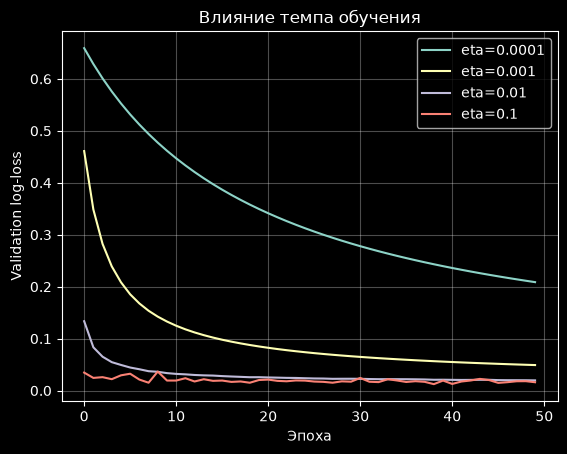

,final_train_loss,final_val_loss,weight_norm
0.0001,0.2153,0.2088,0.7944
0.0010,0.0511,0.0491,2.2124
0.0100,0.0149,0.0197,4.4856
0.1000,0.0048,0.0161,8.7914


In [9]:
## 9. Исследование темпа обучения
eta_values = [0.0001, 0.001, 0.01, 0.1]
eta_runs = {}

for eta in eta_values:
    _, _, history = train_logreg_sgd(
        X_demo_train, y_demo_train_pm,
        X_demo_val, y_demo_val_pm,
        eta=eta, tau=1e-4, epochs=50,
        random_state=RANDOM_STATE,
    )
    eta_runs[eta] = history
    plt.plot(history["val_loss"], label=f"eta={eta}")

plt.xlabel("Эпоха")
plt.ylabel("Validation log-loss")
plt.title("Влияние темпа обучения")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

eta_result = pd.DataFrame({
    eta: {
        "final_train_loss": h["train_loss"].iloc[-1],
        "final_val_loss": h["val_loss"].iloc[-1],
        "weight_norm": h["weight_norm"].iloc[-1],
    }
    for eta, h in eta_runs.items()
}).T
display(eta_result.round(4))

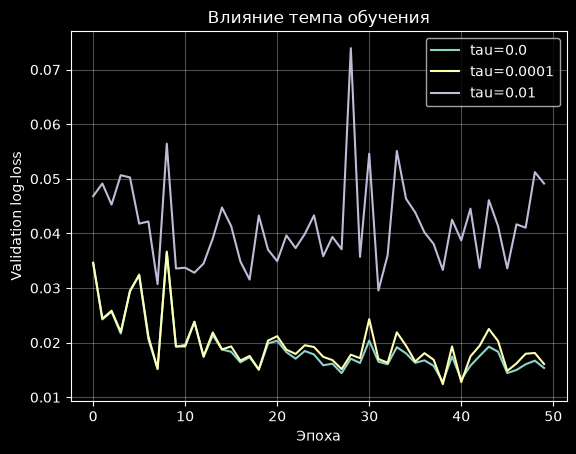

,tau,val_loss,weight_norm
0,0.0000,0.0154,9.8225
1,0.0001,0.0161,8.7914
2,0.0100,0.0491,2.7894


In [10]:
## 10. Исследование регуляризации
best_eta = eta_result["final_val_loss"].idxmin()
tau_values = [0.0, 1e-4, 1e-2]
tau_result = []

for tau in tau_values:
    w_sgd, b_sgd, history = train_logreg_sgd(
        X_demo_train, y_demo_train_pm,
        X_demo_val, y_demo_val_pm,
        eta=float(best_eta), tau=tau, epochs=50,
        random_state=RANDOM_STATE,
    )
    tau_result.append({
        "tau": tau,
        "val_loss": history["val_loss"].iloc[-1],
        "weight_norm": np.linalg.norm(w_sgd),
    })

    plt.plot(history["val_loss"], label=f"tau={tau}")

plt.xlabel("Эпоха")
plt.ylabel("Validation log-loss")
plt.title("Влияние темпа обучения")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

tau_result = pd.DataFrame(tau_result)
display(tau_result.round(4))

In [11]:
## 11. Полный preprocessing pipeline
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = [
    column for column in X_train.columns
    if column not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

sgd_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", SGDClassifier(
        loss="log_loss",
        penalty="l2",
        learning_rate="constant",
        max_iter=2000,
        tol=1e-4,
        random_state=RANDOM_STATE,
    )),
])

In [12]:
## 12. Подбор гиперпараметров SGD
sgd_param_grid = {
    "model__eta0": [0.001, 0.01, 0.1],
    "model__alpha": [1e-6, 1e-4, 1e-2],
}

sgd_search = GridSearchCV(
    estimator=sgd_pipeline,
    param_grid=sgd_param_grid,
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
sgd_search.fit(X_train, y_train)

print("Лучшие параметры SGD:", sgd_search.best_params_)
print("Лучший CV macro-F1:", round(sgd_search.best_score_, 4))

sgd_cv_table = pd.DataFrame(sgd_search.cv_results_)[[
    "param_model__eta0",
    "param_model__alpha",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]].sort_values("rank_test_score")
display(sgd_cv_table.round(4))

Лучшие параметры SGD: {'model__alpha': 0.01, 'model__eta0': 0.01}
Лучший CV macro-F1: 0.9449


,param_model__eta0,param_model__alpha,mean_train_score,mean_test_score,std_test_score,rank_test_score
7,0.010,0.0100,0.9726,0.9449,0.0141,1
6,0.001,0.0100,0.9698,0.9448,0.0174,2
4,0.010,0.0001,0.9908,0.9398,0.0141,3
1,0.010,0.0000,0.9909,0.9392,0.0137,4
3,0.001,0.0001,0.9778,0.9386,0.0172,5
0,0.001,0.0000,0.9778,0.9380,0.0172,6
5,0.100,0.0001,0.9843,0.9355,0.0140,7
2,0.100,0.0000,0.9873,0.9336,0.0115,8
8,0.100,0.0100,0.9445,0.9142,0.0111,9


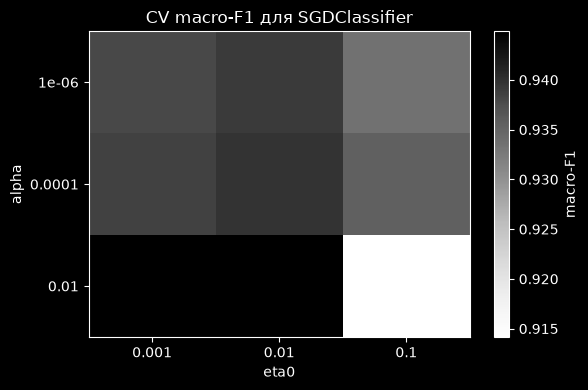

In [13]:
## 13. Тепловая карта CV
pivot = sgd_cv_table.pivot_table(
    index="param_model__alpha",
    columns="param_model__eta0",
    values="mean_test_score",
)

fig, ax = plt.subplots(figsize=(6, 4))
image = ax.imshow(pivot.to_numpy(), cmap="Greys", aspect="auto")
ax.set_xticks(range(len(pivot.columns)), labels=pivot.columns)
ax.set_yticks(range(len(pivot.index)), labels=pivot.index)
ax.set_xlabel("eta0")
ax.set_ylabel("alpha")
ax.set_title("CV macro-F1 для SGDClassifier")
fig.colorbar(image, ax=ax, label="macro-F1")
plt.tight_layout()
plt.show()

In [14]:
## 14. Подбор C для LogisticRegression
logreg_pipeline = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", LogisticRegression(
        max_iter=3000,
        random_state=RANDOM_STATE,
    )),
])

logreg_search = GridSearchCV(
    estimator=logreg_pipeline,
    param_grid={"model__C": [0.01, 0.1, 1.0, 10.0]},
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
)
logreg_search.fit(X_train, y_train)

cv_comparison = pd.DataFrame([
    {
        "model": "DummyClassifier",
        "best_params": "strategy=most_frequent",
        "cv_macro_f1": baseline_summary["f1_macro_cv_mean"],
    },
    {
        "model": "SGDClassifier",
        "best_params": str(sgd_search.best_params_),
        "cv_macro_f1": sgd_search.best_score_,
    },
    {
        "model": "LogisticRegression",
        "best_params": str(logreg_search.best_params_),
        "cv_macro_f1": logreg_search.best_score_,
    },
]).sort_values("cv_macro_f1", ascending=False)

display(cv_comparison.round(4))

candidate_comparison = cv_comparison[
    cv_comparison["model"] != "DummyClassifier"
].reset_index(drop=True)

,model,best_params,cv_macro_f1
1,SGDClassifier,"{'model__alpha': 0.01, 'model__eta0': 0.01}",0.9449
2,LogisticRegression,{'model__C': 0.1},0.9443
0,DummyClassifier,strategy=most_frequent,0.0182


In [15]:
## 15. Финальная оценка на test
def evaluate_classifier(name, estimator, X_eval, y_eval):
    prediction = estimator.predict(X_eval)
    probabilities = estimator.predict_proba(X_eval)
    classes = estimator.classes_

    if len(classes) == 2:
        positive_class = classes[1]
        y_binary = (np.asarray(y_eval) == positive_class).astype(int)
        auc = roc_auc_score(y_binary, probabilities[:, 1])
    else:
        auc = roc_auc_score(
            y_eval, probabilities, labels=classes,
            multi_class="ovr", average="macro",
        )

    return {
        "model": name,
        "accuracy": accuracy_score(y_eval, prediction),
        "precision_macro": precision_score(y_eval, prediction, average="macro", zero_division=0),
        "recall_macro": recall_score(y_eval, prediction, average="macro", zero_division=0),
        "f1_macro": f1_score(y_eval, prediction, average="macro", zero_division=0),
        "roc_auc": auc,
    }

,model,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
0,DummyClassifier,0.1000,0.010,0.1000,0.0182,0.5000
1,SGDClassifier,0.9600,0.961,0.9600,0.9598,0.9979
2,LogisticRegression,0.9675,0.969,0.9675,0.9675,0.9987


              precision    recall  f1-score   support

           1       0.95      1.00      0.98        40
           2       0.93      1.00      0.96        40
           3       1.00      1.00      1.00        40
           4       0.94      0.85      0.89        40
           5       1.00      0.95      0.97        40
           6       0.97      0.95      0.96        40
           7       0.97      0.97      0.97        40
           8       0.91      0.97      0.94        40
           9       1.00      0.95      0.97        40
          10       0.93      0.95      0.94        40

    accuracy                           0.96       400
   macro avg       0.96      0.96      0.96       400
weighted avg       0.96      0.96      0.96       400



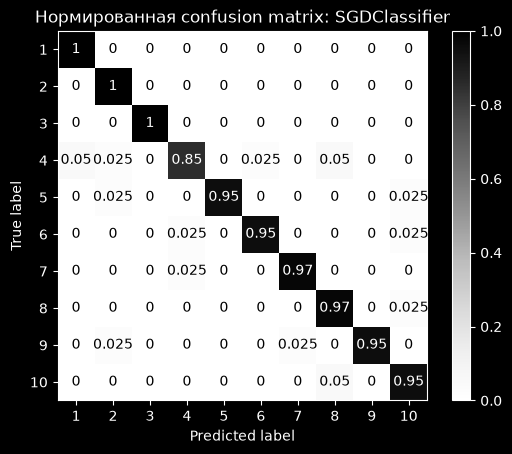

In [16]:
baseline.fit(X_train, y_train)

final_models = {
    "DummyClassifier": baseline,
    "SGDClassifier": sgd_search.best_estimator_,
    "LogisticRegression": logreg_search.best_estimator_,
}

test_results = pd.DataFrame([
    evaluate_classifier(name, model, X_test, y_test)
    for name, model in final_models.items()
])
display(test_results.round(4))

selected_name = candidate_comparison.iloc[0]["model"]
selected_model = final_models[selected_name]
selected_prediction = selected_model.predict(X_test)

print(classification_report(y_test, selected_prediction, zero_division=0))

ConfusionMatrixDisplay.from_estimator(
    selected_model, X_test, y_test,
    normalize="true", cmap="Greys",
)
plt.title(f"Нормированная confusion matrix: {selected_name}")
plt.show()

In [17]:
## 16. Анализ ошибок
error_table = X_test.copy()
error_table["true"] = np.asarray(y_test)
error_table["predicted"] = selected_prediction

selected_probabilities = selected_model.predict_proba(X_test)
error_table["confidence"] = selected_probabilities.max(axis=1)

errors = error_table[
    error_table["true"] != error_table["predicted"]
].sort_values("confidence", ascending=False)

display(errors.head(10))

,att1,att2,att3,att4,att5,att6,att7,att8,att9,att10,...,att58,att59,att60,att61,att62,att63,att64,true,predicted,confidence
602,14.225326,5.820617,3.543279,2.309732,0.874343,3.415838,-1.675583,1.210900,5.672688,-2.826077,...,-1.136077,-0.697318,-0.423091,-1.119801,-1.483761,-0.866623,1.127262,4,8,0.682062
882,-3.185716,-5.169368,-4.394968,7.903034,5.289021,2.059289,-3.149207,-1.183298,-4.053997,1.869081,...,0.264875,-0.127122,0.004635,0.531691,-1.075380,1.609084,-2.257666,5,10,0.655477
649,5.363024,5.736277,2.384048,9.232138,5.200172,2.759709,-1.706314,-5.239243,-0.998453,-4.865503,...,-0.385482,-0.491188,0.309731,0.251703,-0.952100,0.045706,1.064896,4,2,0.650981
652,-2.075872,-1.716042,11.233203,10.750720,3.650975,-0.202983,-0.597334,5.547302,2.055618,-3.589343,...,-0.500451,-0.344159,-2.632412,-0.459460,0.317518,1.320422,-1.406457,4,8,0.578742
1444,4.677450,-7.920971,3.026203,3.442073,4.367340,4.372218,0.650011,-1.942088,-4.856296,-2.489994,...,0.602844,-0.102512,-0.453230,0.326818,0.755351,1.183234,0.477290,8,10,0.522517
792,-5.481667,-1.552178,0.860798,8.869652,-3.167243,0.256607,-8.877839,-0.769970,1.728925,2.786541,...,-0.036585,0.588853,-0.401710,-0.448030,-0.203249,-0.248519,-1.688625,4,1,0.514553
960,-0.187366,7.616859,1.639423,4.620364,5.214698,2.779464,1.042264,-1.661078,9.641357,-2.469626,...,-0.355433,0.622755,-0.787893,-0.405858,-1.143247,-1.307300,-0.628253,5,2,0.488221
1092,-9.080426,-3.572196,0.967463,6.251471,4.208986,-1.407374,-3.711134,1.799571,-6.890486,3.261687,...,-0.002211,-0.527309,-1.215324,1.316192,0.079888,-0.185790,-0.525110,6,4,0.479678
1939,13.387370,-0.243580,9.611562,-4.636392,-0.924634,0.219824,-3.688503,4.349350,-0.299878,-4.871416,...,0.442959,-1.746986,0.012885,-0.776025,-0.405495,1.645901,1.792671,10,8,0.472513
1069,-0.780191,-1.679381,-4.099149,-2.131849,8.548025,-3.862065,-5.112367,-3.424120,2.601123,2.061486,...,0.953733,-1.135762,0.225213,0.701734,-0.408497,-0.591061,-0.923290,6,10,0.471994


In [18]:
## 17. Анализ коэффициентов
feature_names = selected_model.named_steps["prep"].get_feature_names_out()
model = selected_model.named_steps["model"]

class_index = 0
coefficients = model.coef_[class_index]

coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
    "abs_coefficient": np.abs(coefficients),
}).sort_values("abs_coefficient", ascending=False)

display(coefficient_table.head(15))

,feature,coefficient,abs_coefficient
0,num__att1,-1.006667,1.006667
6,num__att7,-0.934140,0.934140
1,num__att2,-0.907004,0.907004
3,num__att4,-0.471681,0.471681
19,num__att20,0.450484,0.450484
9,num__att10,0.442513,0.442513
4,num__att5,-0.436300,0.436300
13,num__att14,0.428139,0.428139
25,num__att26,0.422736,0.422736
18,num__att19,0.420888,0.420888
